# 실습 6 심화 (선택) · SHAP으로 Isolation Forest 이상 점수 설명

추가 설치: `.venv\Scripts\python -m pip install -r requirements-advanced.txt` (shap, matplotlib)

SHAP 값은 한 건의 모델 출력을 피처별 몫으로 나눈 것입니다. Isolation Forest는 '평균 경로 길이'(짧을수록 이상)를 나누므로, 부호를 바꿔 이상 기여도(클수록 이상 쪽으로 민 피처)로 봅니다.

In [1]:
import os
import numpy as np
import pandas as pd

assert os.path.exists("../data/processed/train.csv"), "05a_data_preprocessing.ipynb를 먼저 실행하세요"
train = pd.read_csv("../data/processed/train.csv", dtype={"dsport": str})
test = pd.read_csv("../data/processed/test.csv", dtype={"dsport": str})
print(f"학습 {len(train)}건 (공격 {train['label'].sum()}) / 평가 {len(test)}건 (공격 {test['label'].sum()})")

학습 3520건 (공격 166) / 평가 1509건 (공격 71)


In [2]:
DESIGNED = ["log_ct_srv_dst", "log_ct_dst_ltm", "log_ct_src_dport_ltm",       # 연결 행위
            "log_sbytes_vs_svc", "log_dbytes_vs_svc", "log_rate_vs_svc",      # 규모 (서비스 평소 대비)
            "byte_ratio_vs_svc", "pkt_ratio_vs_svc"]                          # 방향 (서비스 평소 대비)
CATS = ["DoS", "Reconnaissance", "Exploits"]

## 모델 (05b C 구성과 같은 설정)과 SHAP 계산

In [3]:
import shap
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

sc = StandardScaler().fit(train[DESIGNED])
model = IsolationForest(n_estimators=300, contamination=0.05, random_state=42).fit(sc.transform(train[DESIGNED]))
X = sc.transform(test[DESIGNED])
test["score"] = -model.score_samples(X)
test["alert"] = (model.predict(X) == -1).astype(int)

sv = shap.TreeExplainer(model).shap_values(X)                         # 수 초~수십 초
contrib = pd.DataFrame(-sv, columns=DESIGNED, index=test.index)       # 부호 반전: 클수록 이상 쪽
print("SHAP 합과 이상 점수의 상관:", round(np.corrcoef(contrib.sum(axis=1), test["score"])[0, 1], 3), "(1에 가까우면 정상)")

C:\Users\KISIA\Desktop\AI보안\makeAIS\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP 합과 이상 점수의 상관: 0.996 (1에 가까우면 정상)


## 1) 전체 중요도: 평균 |SHAP| (05b 묶음 제외 실험과 비교)

In [4]:
contrib.abs().mean().sort_values(ascending=False).round(3)

log_ct_src_dport_ltm    0.594
pkt_ratio_vs_svc        0.479
byte_ratio_vs_svc       0.378
log_rate_vs_svc         0.310
log_ct_srv_dst          0.279
log_dbytes_vs_svc       0.278
log_ct_dst_ltm          0.272
log_sbytes_vs_svc       0.265
dtype: float64

## 2) 경보 건의 유형별 평균 이상 기여도 상위 3개 (Normal = 오탐)

In [5]:
for cat in ["DoS", "Reconnaissance", "Exploits", "Normal"]:
    m = (test["attack_cat"] == cat) & (test["alert"] == 1)
    top = contrib[m].mean().sort_values(ascending=False).head(3)
    print(f"{cat:<15} {m.sum():>3}건:", ", ".join(f"{k} {v:+.2f}" for k, v in top.items()))

DoS              12건: log_dbytes_vs_svc +1.69, byte_ratio_vs_svc +1.64, pkt_ratio_vs_svc +1.61
Reconnaissance    3건: byte_ratio_vs_svc +2.45, log_dbytes_vs_svc +2.37, pkt_ratio_vs_svc +1.29
Exploits          7건: byte_ratio_vs_svc +1.96, log_dbytes_vs_svc +1.78, pkt_ratio_vs_svc +1.59
Normal           64건: log_dbytes_vs_svc +1.84, log_rate_vs_svc +1.69, byte_ratio_vs_svc +1.29


## 3) 유형별 대표 경보 1건: 상위 3개 피처를 LLM 근거 문장으로

In [6]:
MEANING = {"log_ct_srv_dst": "같은 서비스·목적지 연결 수", "log_ct_dst_ltm": "같은 목적지 연결 수",
           "log_ct_src_dport_ltm": "같은 출발지·목적지 포트 연결 수", "log_sbytes_vs_svc": "서비스 평소 대비 송신 바이트",
           "log_dbytes_vs_svc": "서비스 평소 대비 수신 바이트", "log_rate_vs_svc": "서비스 평소 대비 초당 패킷 수",
           "byte_ratio_vs_svc": "서비스 평소 대비 송신 바이트 비중", "pkt_ratio_vs_svc": "서비스 평소 대비 송신 패킷 비중"}
Z = pd.DataFrame(X, columns=DESIGNED, index=test.index)              # 표준화 값 (0 = 학습셋 평균)

picks = test[test["alert"] == 1].sort_values("score", ascending=False).groupby("attack_cat").head(1)
for idx, row in picks.iterrows():
    top = contrib.loc[idx].sort_values(ascending=False).head(3)
    text = " / ".join(f"{MEANING[f]} {'높음' if Z.loc[idx, f] > 0 else '낮음'} (표준화 {Z.loc[idx, f]:+.1f})" for f in top.index)
    print(f"[{row['attack_cat']}] 서비스 {row['service']} · 점수 {row['score']:.3f}\n   근거 문장: {text}\n")

[Normal] 서비스 dns · 점수 0.706
   근거 문장: 서비스 평소 대비 송신 바이트 비중 높음 (표준화 +5.6) / 서비스 평소 대비 송신 패킷 비중 높음 (표준화 +5.0) / 서비스 평소 대비 수신 바이트 낮음 (표준화 -7.4)

[Exploits] 서비스 http · 점수 0.689
   근거 문장: 서비스 평소 대비 송신 바이트 비중 높음 (표준화 +7.3) / 서비스 평소 대비 수신 바이트 낮음 (표준화 -5.1) / 서비스 평소 대비 송신 패킷 비중 높음 (표준화 +4.2)

[DoS] 서비스 http · 점수 0.684
   근거 문장: 서비스 평소 대비 송신 바이트 비중 높음 (표준화 +6.6) / 서비스 평소 대비 수신 바이트 낮음 (표준화 -5.1) / 서비스 평소 대비 송신 패킷 비중 높음 (표준화 +4.2)

[Reconnaissance] 서비스 http · 점수 0.638
   근거 문장: 서비스 평소 대비 송신 바이트 비중 높음 (표준화 +5.5) / 서비스 평소 대비 수신 바이트 낮음 (표준화 -5.1) / 서비스 평소 대비 송신 패킷 비중 높음 (표준화 +2.8)



## 4) 그림

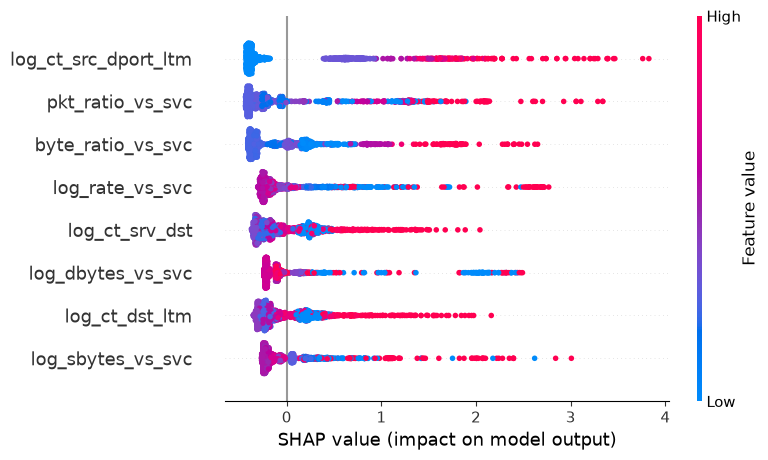

In [7]:
shap.summary_plot(-sv, pd.DataFrame(X, columns=DESIGNED))     # 오른쪽일수록 이상 쪽으로 민 값

### 토론
- 3)의 오탐 사례(Normal)는 어떤 피처 때문에 경보가 났는지 보고 개선점을 찾습니다.
- SHAP은 '모델이 왜 이렇게 판단했는지'를 설명할 뿐, 그 판단이 맞는지는 알려주지 않습니다.